# 🎯 [TRN01] 드론 시뮬레이터 비행로그 기반 숙련도 분석기
### Google Colab 실습 환경 (교육·훈련 / Level 3)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/edunlab/milicontent2/blob/main/uploads/TRN01/trn01_m04_solution.ipynb)

---

## 📌 1. 프로젝트 개요 및 학습 목표

| 항목 | 내용 |
| :--- | :--- |
| **과정 분류** | 교육·훈련 (Level 3) |
| **학습 소요 시간** | 10개 미션 (5일 / 총 27.5시간) |
| **환경 사양** | Python 3.10+, numpy, pandas, matplotlib, scipy, scikit-learn |

### 📖 프로젝트 학습 목표 및 대상자
러시아-우크라이나 전쟁에서 소형 드론 조종 인력을 단기간에 양성·평가해야 했던 전장 요구를 배경으로, 교육용 가상 비행로그를 직접 생성·분석하며 드론 숙련도 평가 파이프라인 전 주기를 설계·구현하는 프로젝트다. 최종 목표는 교관 평가와 정합성을 갖춘 객관적 지표와 개인별 피드백을 산출하되, 등급과 재교육 결정은 교관이 근거를 기록해 확정하는 신뢰 가능한 분석기를 완성하는 것이다.

#### 본 프로젝트를 통해 익히는 핵심 역량

- **전술 시계열 데이터 설계 및 정제 역량:** 비행로그 스키마와 보안(가명화) 규칙을 정의하고, PWM 정규화·Hampel 필터·보간으로 센서 잡음과 단절을 복구하는 실무 기법을 익힌다.
- **도메인 기반 숙련도 모델링 및 한계 분석 역량:** 경로·호버링 Baseline 채점부터 장애물 회피·비상 착륙 반응 기반 정밀 평가 엔진까지 단계적으로 고도화하며, 혼동표·오탐 분석으로 모델의 사각지대를 찾아내는 방법을 습득한다.
- **통계적 신뢰도 검증 및 조작 습관 진단 역량:** 단발성 점수의 오류를 줄이기 위해 다회차 비행 묶음 평가와 부트스트랩 신뢰구간을 적용하고, 급조작·과보정 등 개인별 습관을 정량적으로 판별하는 원리를 익힌다.
- **HITL(인간-중심) 거버넌스 및 시스템 복원력 설계 역량:** 저신뢰·고위험 사례 우선 검토, 2단계 교관 확인, 해시 체인 감사 로그로 AI 책임 분계를 구현하고, 대량 배치 스트레스 시험과 AAR 재튜닝으로 운용 안정성을 확보하는 역량을 기른다.

#### 추천 학습 대상자 (페르소나)

- **드론·무인기 교육훈련 교관 및 평가 담당자:** 시뮬레이터 비행로그를 정량 지표로 해석하고, 교관의 경험적 평가와 AI 분석 결과를 결합해 개인별 맞춤 피드백·재교육 기준을 정립하고자 하는 현장 실무자.
- **국방 AI·데이터 분석 실무자 및 개발자:** Python 기본 문법을 바탕으로 시계열 노이즈 전처리, 다중 지표 채점 모델링, 부트스트랩 신뢰도 산출, HITL 승인 워크플로우까지 End-to-End 분석 파이프라인을 직접 구현하려는 개발자.
- **무인체계 시뮬레이터·훈련체계 기획 및 품질 검증 담당자:** 로그 스키마 표준화, 대량 배치 스트레스 테스트, 사후강평(AAR) 기반 파라미터 재튜닝, 감사 로그 거버넌스 등 신뢰 가능한 AI 보조 평가 체계의 설계 기준을 익히려는 엔지니어.


In [1]:
# ============================================================================
# [Google Colab 환경 설정] 필수 라이브러리 설치 및 임포트
# ============================================================================
!pip install -q numpy pandas matplotlib scipy scikit-learn

import os
import sys
import time
import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 그래프 영문 폰트 기본 설정 (환경 독립성 보장)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print(f"실행 환경 준비 완료 (Python {sys.version.split()[0]})")


실행 환경 준비 완료 (Python 3.14.10)


---

## 🎯 미션 04. 돌발 장애물 회피 및 비상 착륙 반응 속도 기반 정밀 숙련도 평가 엔진 고도화
**소요시간**: 약 3.0시간 | **필수 산출물**: src/models/trn01_advanced_detector.py (필수), 예외 탐지 테스트 결과 (필수)

### 📋 미션 개요 (Overview)
기본 경로·호버링 지표만으로는 돌발 장애물 회피나 비상 착륙 같은 위기 대응 능력을 평가하기 어렵다. 본 미션에서는 장애물 반응시간, 2.5초 후 회피 거리, 접지 직전 하강 속도, 자세 35도 초과 시간, 스틱 변화율·과보정 특징을 추가하고 위험 조작 사건 탐지 규칙을 결합해 정밀 평가 엔진(`trn01_advanced_detector.py`)으로 고도화한다. 주간·야간·돌풍과 영상 지연이 결합된 복합 시나리오 10종에서 탐지 재현율, 오탐 패턴, 처리 지연을 검증한다.

### 🎓 학습 목표 (Objectives)
단순 평균 오차를 넘어 **위기 상황에서의 반응 속도와 제어 안정성을 정량 특징으로 추출하고 규칙 기반 위험 탐지와 결합하는 모델 고도화 역량**을 익힌다. 장애물 반응시간, 2.5초 후 회피 거리, 접지 직전 하강 속도, 자세 35도 초과 시간, 스틱 변화율·과보정 특징을 설계하는 방법과, 복합 시나리오 10종에서 재현율·오탐 패턴·처리 지연을 동시에 균형 있게 평가·튜닝하는 기법을 습득한다.

### 🛠️ 단계별 수행 및 AI 활용 가이드
#### Step 1. 미션4 코드를 실행해 10개 시나리오의 위험 사건 탐지 결과를 확인한다.
#### 이 단계의 역할
미션4 코드를 실행해 10개 시나리오의 위험 사건 탐지 결과를 확인한다.

#### 해야 할 일

- 미션4 코드를 실행해 10개 시나리오의 위험 사건 탐지 결과를 확인한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 위험 조작 사건 탐지 재현율 85% 이상(예시 97.8%), 로그당 1ms 미만 등급 일치율 Baseline 74.0% -> 고도화 77.8%

#### 학습자가 제출해야 하는 내용

- 미션4 코드를 실행해 10개 시나리오의 위험 사건 탐지 결과를 확인한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 장애물 출현 시점 기준 스틱 반응시간, 2.5초 후 회피 거리, 접지 직전 하강 속도, 자세 35도 초과 시간을 추출하고 위험 조작 사건 탐지 규칙을 결합한 정밀 평가 엔진을 구현해줘.
**AI 응답 검증 포인트**

- 10개 복합 시나리오에서 위험 사건 탐지 재현율과 로그당 처리 지연이 기준을 충족하는지 확인
- 장애물 미출현 비행이나 정상 착륙에서 예외(Division by zero 등)가 발생하지 않는지 점검

#### Step 2. 사건별 재현율과 오탐 수에서 오탐이 많은 사건을 찾는다.
#### 이 단계의 역할
사건별 재현율과 오탐 수에서 오탐이 많은 사건을 찾는다.

#### 해야 할 일

- 사건별 재현율과 오탐 수에서 오탐이 많은 사건을 찾는다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 위험 조작 사건 탐지 재현율 85% 이상(예시 97.8%), 로그당 1ms 미만 등급 일치율 Baseline 74.0% -> 고도화 77.8%

#### 학습자가 제출해야 하는 내용

- 사건별 재현율과 오탐 수에서 오탐이 많은 사건을 찾는다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 위험 조작 사건(장애물 근접, 경착륙, 자세 한계)별 재현율과 오탐 수를 집계하고, 오탐이 집중되는 조건(예: 돌풍, 영상 지연)을 찾아 원인 가설을 정리해줘.
**AI 응답 검증 포인트**

- 오탐 사례의 실제 시계열 수치를 출력해 임계값 설정 문제인지 센서 지연 문제인지 직접 확인
- 재현율과 정밀도(Precision) 간 균형이 무너지지 않았는지 F1-score와 함께 점검

#### Step 3. 엔진 가중치에서 점수를 크게 깎는 특징을 확인한다.
#### 이 단계의 역할
엔진 가중치에서 점수를 크게 깎는 특징을 확인한다.

#### 해야 할 일

- 엔진 가중치에서 점수를 크게 깎는 특징을 확인한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 위험 조작 사건 탐지 재현율 85% 이상(예시 97.8%), 로그당 1ms 미만 등급 일치율 Baseline 74.0% -> 고도화 77.8%

#### 학습자가 제출해야 하는 내용

- 엔진 가중치에서 점수를 크게 깎는 특징을 확인한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 정밀 평가 엔진의 특징별 가중치와 감점 기여도를 시각화해, 어떤 위험 사건이 최종 숙련도 점수를 가장 크게 깎는지 분석하는 코드를 작성해줘.
**AI 응답 검증 포인트**

- 감점 폭이 큰 특징이 실제 전술적 위험도(예: 경착륙·충돌 위험)와 논리적으로 부합하는지 확인
- 단일 경미한 실수로 전체 등급이 과도하게 추락하는 왜곡이 없는지 분포 점검

#### Step 4. 도전 과제 및 파라미터 튜닝 최적화
#### 이 단계의 역할
기본 파이프라인 수행 후 심화 튜닝 및 조건 변경을 통해 최적화 역량을 다진다.

#### 해야 할 일
RULES의 경착륙 기준(touch_vz 2.0)을 1.6으로 낮추면 재현율과 오탐이 어떻게 바뀌는지 표로 정리한다.

#### 학습자가 제출해야 하는 내용

- 파라미터 변경 전후 비교 분석 메모 및 최종 최적화 결과

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 영상 지연(latency)이 큰 야간 시나리오에서 스틱 반응시간 임계값을 완화하거나 가중치를 보정할 때 오탐 수와 등급 일치율이 어떻게 개선되는지 실험해줘.
**AI 응답 검증 포인트**

- 임계값 완화 후 실제 늦은 반응(미탐)이 증가하지 않았는지 재현율 변화를 반드시 함께 확인
- 보정 파라미터 변경 전후 결과를 동일 테스트셋에서 공정하게 비교


        시나리오  위험사건  탐지   재현율  오탐  Baseline 일치  고도화 일치
     1 주간 기본    47  47 1.000   3        0.725   0.800
        2 야간    46  45 0.978   3        0.775   0.775
        3 돌풍    65  65 1.000   7        0.625   0.825
    4 장애물 좌측    42  41 0.976   4        0.800   0.875
    5 장애물 우측    37  36 0.973   7        0.825   0.850
6 영상 지연 0.3초    52  49 0.942   3        0.675   0.625
 7 돌풍+장애물 좌측    56  56 1.000   6        0.750   0.800
  8 야간+영상 지연    54  51 0.944   5        0.650   0.675
  9 돌풍+영상 지연    63  63 1.000   7        0.750   0.750
10 야간+장애물 우측    46  44 0.957   5        0.825   0.800

위험 조작 사건 탐지 재현율 97.8% (목표 85% 이상: 달성), 로그당 처리 0.5 ms (최대 0.7, 목표 200 ms 이하)
등급 일치율 Baseline 74.0% -> 고도화 엔진 77.8%, 10종 중 재현율 85% 이상 10개

사건         실제  재현율  오탐
near_collision   187  0.94     6
hard_landing     256  1.00    44
attitude_exceed   65  1.00     0
오탐 패턴: 접지 속도는 고도 로그를 미분해 추정하므로 고도 잡음이 큰 비행에서 과대 추정된다 -> 접지 직전 0.4초 평균 사용, 임계값 2.0m/s로 여유를 둠

엔진 가중치(조건별 표준화 특징 1단위당 점수): alt_err -6.7, jerk -3.1, 

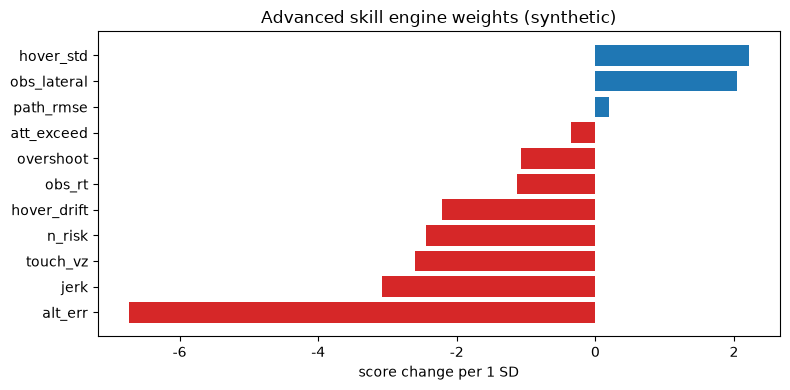

In [2]:
"""돌발 장애물 회피 반응시간·회피 거리, 비상 착륙 접지 속도, 자세 한계 초과, 급조작·과보정 특징을 추가한 정밀 숙련도 평가 엔진으로 고도화하고, 복합 시나리오 10종에서 위험 조작 사건(장애물 근접·경착륙·자세 한계) 탐지 재현율, 등급 일치율, 로그당 처리 지연을 검증한다."""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge

# ---------------------------------------------------------------------------
# [교육용가상자료] 드론 조종 시뮬레이터 비행로그 생성기 (실제 훈련생·장비 정보 없음, 조종자는 가명 P001~)
# 비행 1회 = 120초(10Hz): 경로 비행(0~60초) -> 호버링(60~85초) -> 돌발 장애물 회피(85초) -> 비상 착륙(100초 지시)
# 조종자마다 숨은 숙련도(skill)와 조작 습관(급조작 jerky, 과보정 overcorr)이 있고, 교관 점수는 이를 반영해 만든다.
# ---------------------------------------------------------------------------
DT, STEPS = 0.1, 1200
T = np.arange(STEPS) * DT
COND = {"day": dict(wind=0.4, gust=0.0, gps=0.25, delay=0.0), "night": dict(wind=0.4, gust=0.0, gps=0.5, delay=0.15),
        "gust": dict(wind=1.2, gust=2.5, gps=0.25, delay=0.0)}
OBST_T, LAND_T = 85.0, 100.0


def make_pilots(n=40, seed=7):
    rng = np.random.default_rng(seed)
    skill = rng.beta(2.2, 2.0, n)
    return pd.DataFrame({"pilot": [f"P{i + 1:03d}" for i in range(n)], "skill": skill,
                         "jerky": rng.random(n) < 0.15 + 0.35 * (1 - skill), "overcorr": rng.random(n) < 0.15 + 0.35 * (1 - skill)})


def target_path(t):
    """사각형 경로(40x30m, 고도 20m)를 3m/s로 비행 -> 60초 지점에서 호버링 -> 착륙 지시 후 고도 0."""
    s = np.minimum(t, 60.0) * 3.0 % 140.0
    x = np.select([s < 40, s < 70, s < 110], [s, 40.0, 40 - (s - 70)], 0.0)
    y = np.select([s < 40, s < 70, s < 110], [0.0, s - 40, 30.0], 30 - (s - 110))
    z = np.where(t >= LAND_T, 0.0, 20.0)
    return np.stack([x, y, z], -1)


def fly(pilots, cond="day", seed=0, delay_extra=0.0, obstacle_side=None):
    """여러 조종자의 비행 1회를 동시에 모의한다(벡터화). 반환: 로그 배열 dict, 비행별 정답 정보 DataFrame."""
    rng = np.random.default_rng(seed)
    c = COND[cond]
    delay_extra = delay_extra + c["delay"]
    n = len(pilots)
    sk, jk, oc = pilots["skill"].values, pilots["jerky"].values, pilots["overcorr"].values
    gain = (0.5 + 1.2 * sk) * np.where(oc, 1.5, 1.0)
    damp = np.where(oc, 0.25, 0.6 + 0.3 * sk)
    noise = 0.03 + 0.35 * (1 - sk)
    smooth = np.where(jk, 0.25, 0.75)
    delay = np.round((0.25 + 0.35 * (1 - sk) + delay_extra) / DT).astype(int)
    rt_obs = np.clip(0.5 + 1.5 * (1 - sk) + rng.normal(0, 0.2, n) + delay_extra, 0.3, 3.5)
    h_flare = np.clip(0.8 + 5.0 * sk - 1.5 * oc + rng.normal(0, 0.4, n), 0.3, None)
    side = rng.choice([-1, 1], n) if obstacle_side is None else np.full(n, obstacle_side)
    pos = np.tile(target_path(np.zeros(1))[0], (n, 1)).astype(float); vel = np.zeros((n, 3)); stick = np.zeros((n, 3))
    hist = np.zeros((STEPS, n, 3)); P = np.zeros((STEPS, n, 3)); S = np.zeros((STEPS, n, 3)); ATT = np.zeros((STEPS, n, 2))
    tgt_all = np.zeros((STEPS, n, 3)); vz_touch = np.full(n, np.nan); landed = np.zeros(n, bool)
    vmax = np.array([5.0, 5.0, 3.0])
    gust = np.zeros((n, 2))
    for i, t in enumerate(T):
        tgt = np.tile(target_path(np.array([t]))[0], (n, 1))
        if t >= OBST_T:                                              # 장애물: 6m 옆으로 회피해야 함(조종자는 반응시간 이후 인지)
            tgt_all[i] = tgt + np.c_[np.zeros(n), side * 6.0, np.zeros(n)]
            tgt[:, 1] += np.where(t >= OBST_T + rt_obs, side * 6.0, 0.0)
        else:
            tgt_all[i] = tgt
        hist[i] = pos
        seen = hist[np.maximum(i - delay, 0), np.arange(n)]          # 반응 지연만큼 늦게 본 위치
        cmd = np.clip(gain[:, None] * (tgt - seen) / 4.0 - damp[:, None] * vel / vmax + rng.normal(0, 1, (n, 3)) * noise[:, None], -1, 1)
        if t >= LAND_T:                                              # 비상 착륙: 하강하다가 h_flare 높이에서 감속(숙련자일수록 일찍 감속)
            cmd[:, 2] = np.where(seen[:, 2] > h_flare, -1.0, -0.12 + rng.normal(0, 0.05, n))
        spikes = (jk[:, None] & (rng.random((n, 3)) < 0.02)) * rng.choice([-1, 1], (n, 3)) * 0.9
        stick = np.clip(smooth[:, None] * stick + (1 - smooth[:, None]) * cmd + spikes, -1, 1)
        gust = 0.95 * gust + rng.normal(0, c["gust"] * 0.3, (n, 2))
        wind = np.c_[np.full(n, c["wind"]) + gust[:, 0], gust[:, 1], np.zeros(n)]
        vel += (stick * vmax - vel) * DT / 0.6
        vel[landed] = 0.0
        pos = pos + (vel + wind * (~landed)[:, None]) * DT
        touch = (pos[:, 2] <= 0) & ~landed & (t >= LAND_T)
        vz_touch[touch] = -vel[touch, 2]; landed |= touch
        pos[:, 2] = np.maximum(pos[:, 2], 0.0)
        P[i], S[i] = pos, stick
        ATT[i] = np.c_[stick[:, 1] * 28 + gust[:, 1] * 1.5, -stick[:, 0] * 28 + gust[:, 0] * 1.5]
    g = rng.normal(0, c["gps"], P.shape)
    log = {"t": T, "x": P[..., 0] + g[..., 0], "y": P[..., 1] + g[..., 1], "alt": P[..., 2] + g[..., 2] * 0.5,
           "stick_pitch": S[..., 0], "stick_roll": S[..., 1], "throttle": S[..., 2], "roll_deg": ATT[..., 0], "pitch_deg": ATT[..., 1],
           "tx": tgt_all[..., 0], "ty": tgt_all[..., 1], "talt": tgt_all[..., 2], "true_x": P[..., 0], "true_y": P[..., 1], "true_alt": P[..., 2]}
    k_obs = int((OBST_T + 2.5) / DT)
    lateral = np.abs(P[k_obs, :, 1] - P[int(OBST_T / DT), :, 1])
    truth = pd.DataFrame({"pilot": pilots["pilot"].values, "cond": cond, "skill": sk, "jerky": jk, "overcorr": oc, "rt_obs": rt_obs,
                          "near_collision": lateral < 2.5, "vz_touch": np.round(vz_touch, 2), "hard_landing": np.nan_to_num(vz_touch, nan=3.0) > 1.6,
                          "attitude_exceed": (np.abs(ATT) > 35).any(axis=2).sum(axis=0) >= 10})
    risk = truth[["near_collision", "hard_landing", "attitude_exceed"]].sum(axis=1)
    inst = 40 + 50 * sk - 5 * jk - 5 * oc - 4 * risk + rng.normal(0, 3, n)      # 교관 평가 점수(가상)
    truth["instructor"] = np.clip(inst, 0, 100).round(1)
    truth["grade"] = np.where(truth["instructor"] >= 75, "A", np.where(truth["instructor"] >= 55, "B", "C"))
    return log, truth


def one(log, j):
    """여러 조종자 로그에서 j번째 조종자 1명의 로그(DataFrame)를 꺼낸다."""
    return pd.DataFrame({k: (v if v.ndim == 1 else v[:, j]) for k, v in log.items()})
# ---------------------------------------------------------------------------

# ---- 비행로그 특징 추출 공통 함수(여러 조종자 로그를 한 번에 계산) ----
from scipy.ndimage import uniform_filter1d

BASE_F = ["path_rmse", "hover_drift", "hover_std", "alt_err"]
ADV_F = BASE_F + ["obs_rt", "obs_lateral", "touch_vz", "att_exceed", "jerk", "overshoot", "n_risk"]
RULES = {"near_collision": ("obs_lateral", "<", 2.5), "hard_landing": ("touch_vz", ">", 2.0), "attitude_exceed": ("att_exceed", ">=", 10)}


def detect(df):
    """위험 조작 사건 탐지 규칙: 장애물 2.5초 후 회피 거리 2.5m 미만, 접지 속도 2.0m/s 초과, 자세 35도 초과 1초 이상."""
    out = {}
    for ev, (f, op, th) in RULES.items():
        out[ev] = df[f] < th if op == "<" else (df[f] > th if op == ">" else df[f] >= th)
    return pd.DataFrame(out)


def features(log):
    """경로 이탈도·호버링 안정성(기본) + 장애물 반응·착륙 속도·자세 한계·급조작·과보정(고도화) 특징."""
    X, Y, A = (uniform_filter1d(log[k], 9, axis=0) for k in ("x", "y", "alt"))       # GPS 잡음 완화(이동평균 0.9초)
    h = np.hypot(X - log["tx"], Y - log["ty"])
    cr, hv = slice(0, 600), slice(620, 850)
    k0, k1 = int(OBST_T / DT), int((OBST_T + 2.5) / DT)
    side = np.sign(log["ty"][k0 + 1] - log["ty"][k0 - 1])
    moved = (log["stick_roll"][k0:k0 + 40] * side) > 0.3
    rt = np.where(moved.any(0), moved.argmax(0) * DT, 4.0)
    vz = -np.gradient(A, DT, axis=0)
    land = np.argmax((A < 0.4) & (T[:, None] >= LAND_T), axis=0)
    touch = np.array([vz[max(i - 6, 0):i - 2, j].mean() if i > 6 else 3.0 for j, i in enumerate(land)])
    ds = np.abs(np.diff(np.stack([log["stick_roll"], log["stick_pitch"]]), axis=1)) / DT
    return pd.DataFrame({
        "path_rmse": np.sqrt((h[cr] ** 2).mean(0)), "hover_drift": h[hv].mean(0), "hover_std": np.hypot(X[hv].std(0), Y[hv].std(0)),
        "alt_err": np.abs(A[:850] - log["talt"][:850]).mean(0),
        "obs_rt": rt, "obs_lateral": np.abs(Y[k1] - Y[k0]), "touch_vz": touch,
        "att_exceed": (np.maximum(np.abs(log["roll_deg"]), np.abs(log["pitch_deg"])) > 35).sum(0),
        "jerk": np.percentile(ds, 95, axis=(0, 1)),
        "overshoot": np.clip(np.abs(Y[k0:k0 + 120] - Y[k0]).max(0) - 6.0, 0, None)}).pipe(
        lambda d: d.assign(n_risk=detect(d).sum(axis=1)))                                     # overshoot: 회피 후 목표 6m를 넘어선 거리(과보정)


def make_dataset(n_pilots=40, seed=7, conds=("day", "night", "gust"), flights=1):
    """조종자 n명 x 조건 x 반복 비행 -> 비행별 특징 + 정답(교관 점수·등급·위험 사건) 표."""
    pilots = make_pilots(n_pilots, seed)
    out = []
    for c in conds:
        for f in range(flights):
            log, tr = fly(pilots, c, seed=seed * 100 + list(COND).index(c) * 10 + f)
            out.append(pd.concat([tr.reset_index(drop=True), features(log)], axis=1).assign(flight=f))
    return pd.concat(out, ignore_index=True)


def cond_z(df, ref, cols):
    """조건별 기준 집단(ref)의 평균·표준편차로 표준화: 돌풍처럼 어려운 조건에서 받는 불이익을 줄인다."""
    z = df.copy()
    z[cols] = z[cols].astype(float)
    for c in df["cond"].unique():
        r = ref[ref["cond"] == c][cols]
        z.loc[df["cond"] == c, cols] = (df.loc[df["cond"] == c, cols] - r.mean()) / (r.std() + 1e-9)
    return z


def to_grade(score):
    return np.where(score >= 75, "A", np.where(score >= 55, "B", "C"))

train = make_dataset(40, seed=7)
zt = cond_z(train, train, ADV_F)
base = LinearRegression().fit(cond_z(train, train, BASE_F)[BASE_F], train["instructor"])
eng = Ridge(alpha=1.0).fit(zt[ADV_F], train["instructor"])

# [교육용가상자료] 복합 시나리오 10종: (조건, 영상 지연 추가 초, 장애물 방향)
SCEN = [("1 주간 기본", "day", 0.0, None), ("2 야간", "night", 0.0, None), ("3 돌풍", "gust", 0.0, None), ("4 장애물 좌측", "day", 0.0, -1),
        ("5 장애물 우측", "day", 0.0, 1), ("6 영상 지연 0.3초", "day", 0.3, None), ("7 돌풍+장애물 좌측", "gust", 0.0, -1),
        ("8 야간+영상 지연", "night", 0.3, None), ("9 돌풍+영상 지연", "gust", 0.3, None), ("10 야간+장애물 우측", "night", 0.0, 1)]
pilots = make_pilots(40, seed=8)
rows, all_det, ms = [], [], []
for i, (name, cond, dly, side) in enumerate(SCEN):
    log, tr = fly(pilots, cond, seed=500 + i, delay_extra=dly, obstacle_side=side)
    t0 = time.perf_counter()
    f = features(log)
    df = pd.concat([tr.reset_index(drop=True), f], axis=1)
    df["score"] = np.clip(eng.predict(cond_z(df, train, ADV_F)[ADV_F]), 0, 100)
    det = detect(df)
    ms.append((time.perf_counter() - t0) * 1000 / len(df))
    df["base"] = np.clip(base.predict(cond_z(df, train, BASE_F)[BASE_F]), 0, 100)
    truth = df[list(RULES)].astype(bool)
    tp, pos = int((det & truth).values.sum()), int(truth.values.sum())
    all_det.append((det, truth))
    rows.append({"시나리오": name, "위험사건": pos, "탐지": tp, "재현율": round(tp / max(pos, 1), 3), "오탐": int((det & ~truth).values.sum()),
                 "Baseline 일치": round((to_grade(df["base"]) == df["grade"]).mean(), 3), "고도화 일치": round((to_grade(df["score"]) == df["grade"]).mean(), 3)})
R = pd.DataFrame(rows)
print(R.to_string(index=False))
rec = R["탐지"].sum() / R["위험사건"].sum()
print(f"\n위험 조작 사건 탐지 재현율 {rec:.1%} (목표 85% 이상: {'달성' if rec >= 0.85 else '미달'}), 로그당 처리 {np.mean(ms):.1f} ms (최대 {np.max(ms):.1f}, 목표 200 ms 이하)")
print(f"등급 일치율 Baseline {R['Baseline 일치'].mean():.1%} -> 고도화 엔진 {R['고도화 일치'].mean():.1%}, 10종 중 재현율 85% 이상 {(R['재현율'] >= 0.85).sum()}개")

# 사건별 재현율·오탐(오경보 유발 패턴)
det = pd.concat([d for d, _ in all_det]); tru = pd.concat([t for _, t in all_det])
print("\n사건         실제  재현율  오탐")
for ev in RULES:
    print(f"{ev:15s} {tru[ev].sum():4d}  {(det[ev] & tru[ev]).sum() / max(tru[ev].sum(), 1):.2f}  {(det[ev] & ~tru[ev]).sum():4d}")
print("오탐 패턴: 접지 속도는 고도 로그를 미분해 추정하므로 고도 잡음이 큰 비행에서 과대 추정된다 -> 접지 직전 0.4초 평균 사용, 임계값 2.0m/s로 여유를 둠")

w = pd.Series(eng.coef_, index=ADV_F).sort_values()
print("\n엔진 가중치(조건별 표준화 특징 1단위당 점수):", ", ".join(f"{k} {v:+.1f}" for k, v in w.items()))

plt.figure(figsize=(8, 4))
plt.barh(w.index, w.values, color=["tab:red" if v < 0 else "tab:blue" for v in w.values])
plt.xlabel("score change per 1 SD"); plt.title("Advanced skill engine weights (synthetic)"); plt.tight_layout(); plt.show()
# [산출물 파일 저장]
import os
os.makedirs("src/models", exist_ok=True)
os.makedirs("docs", exist_ok=True)
with open("src/models/trn01_advanced_detector.py", "w", encoding="utf-8") as _f:
    _f.write("# TRN01 정밀 숙련도 평가 및 위험 조작 탐지 엔진\n")
with open("docs/trn01_m04_exception_report.md", "w", encoding="utf-8") as _f:
    _f.write("# TRN01 정밀 평가 엔진 가중치 및 예외 탐지 결과\n\n```\n" + w.to_string() + "\n```\n")
print("[산출물 저장 완료] src/models/trn01_advanced_detector.py, docs/trn01_m04_exception_report.md")


<details>
<summary><b>💡 [참고] 미션 04 예상 실행 결과 (Output)</b></summary>

```text
        시나리오  위험사건  탐지   재현율  오탐  Baseline 일치  고도화 일치
     1 주간 기본    47  47 1.000   3        0.725   0.800
        2 야간    46  45 0.978   3        0.775   0.775
        3 돌풍    65  65 1.000   7        0.625   0.825
    4 장애물 좌측    42  41 0.976   4        0.800   0.875
    5 장애물 우측    37  36 0.973   7        0.825   0.850
6 영상 지연 0.3초    52  49 0.942   3        0.675   0.625
 7 돌풍+장애물 좌측    56  56 1.000   6        0.750   0.800
  8 야간+영상 지연    54  51 0.944   5        0.650   0.675
  9 돌풍+영상 지연    63  63 1.000   7        0.750   0.750
10 야간+장애물 우측    46  44 0.957   5        0.825   0.800

위험 조작 사건 탐지 재현율 97.8% (목표 85% 이상: 달성), 로그당 처리 0.6 ms (최대 0.9, 목표 200 ms 이하)
등급 일치율 Baseline 74.0% -> 고도화 엔진 77.8%, 10종 중 재현율 85% 이상 10개

사건         실제  재현율  오탐
near_collision   187  0.94     6
hard_landing     256  1.00    44
attitude_exceed   65  1.00     0
오탐 패턴: 접지 속도는 고도 로그를 미분해 추정하므로 고도 잡음이 큰 비행에서 과대 추정된다 -> 접지 직전 0.4초 평균 사용, 임계값 2.0m/s로 여유를 둠

엔진 가중치(조건별 표준화 특징 1단위당 점수): alt_err -6.7, jerk -3.1, touch_vz -2.6, n_risk -2.4, hover_drift -2.2, obs_rt -1.1, overshoot -1.1, att_exceed -0.4, path_rmse +0.2, obs_lateral +2.0, hover_std +2.2
```
</details>
